In [23]:
from anemone.system import Loop, Receiver, lamontagne, getRz, rdtype
import torch
import matplotlib.pyplot as plt
import numpy as np


In [28]:
tx = Loop.square(40.)
rx = Receiver()
R = torch.logspace(torch.log10(tx.min_horizontal_distance(rx)/10.), torch.log10(tx.max_horizontal_distance(rx)*2.), steps=100)


In [ ]:
def geomz0(self, rx, R, ix=500):
    if hasattr(self, 'radius') and rx.xyz.numel()==3 and rx.x==0. and rx.y==0.:
        return self._geomz_circle(rx, R)
    logR = torch.log(R).cpu()
    dR = logR[1]-logR[0]

    rx_xyz = rx.xyz
    n_rec  = len(rx)

    geomz      = torch.zeros((n_rec, )+R.shape, dtype=rdtype)

    R      = R [None, None, :]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    for i in range(len(self)-1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        x1,y1 = p1[..., 0], p1[..., 1]
        x2,y2 = p2[..., 0], p2[..., 1]
        ix = int(100*torch.abs(x2-x1).max())
        
        tmpx = torch.linspace(-1, 1, ix)
        x_samp = tmpx
        x_samp += 1.
        length = torch.abs(x2-x1)/2.


        x_ = (x1[:,None] + length[:,None]*x_samp[None, :])
        dx = (x_[..., 1] - x_[..., 0])[:,None]
        
        x1 = x1[:, None]
        x2 = x2[:, None]
        y1 = y1[:, None, None]
        x_ = x_[:, :, None]
        dx = dx[:, None]


        cr = torch.sqrt(y1**2 + x_**2)
        phi = lamontagne((torch.log(cr)-logR)/dR)
        cs =  -y1 * phi * dx / cr
        geomz += cs.sum(axis=1, keepdims=False)
    return geomz.to(R.device)

In [561]:
# def geomz1(self, rx, R):
#     if hasattr(self, 'radius') and rx.xyz.numel()==3 and rx.x==0. and rx.y==0.:
#         return self._geomz_circle(rx, R)
#     logR = torch.log(R).cpu()
#     cr = R[3:-3]
#     #cr = cr*torch.linspace(0.99, 1.01, len(cr)).to(R.dtype)

#     rx_xyz = rx.xyz
#     n_rec  = len(rx)

#     geomz      = torch.zeros((n_rec, )+R.shape, dtype=rdtype)
    
#     phi_func = Spline(R, log_sampled=True)

#     R      = R [None, None, :]
    
#     lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    
#     for i in range(len(self)-1):
    
#         Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
#         p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
#         p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
#         x1,y1 = p1[..., 0], p1[..., 1]
#         x2,y2 = p2[..., 0], p2[..., 1]

#         cs =  -y1 * (cr**2-y1**2)**-0.5
#         cs[cr**2 > x1.max().item()**2 + y1.max().item()**2] = 0.
#         cs[cr < torch.abs(y1)] = 0.
#         geomz += torch.nan_to_num(phi_func.piecewise_linear_integrate(cr.squeeze(), cs.squeeze()))

#         cs =  -y1 * (cr**2-y1**2)**-0.5
#         cs[cr**2 > x2.max().item()**2 + y1.max().item()**2] = 0.
#         cs[cr < torch.abs(y1)] = 0.
#         geomz += torch.nan_to_num(phi_func.piecewise_linear_integrate(cr.squeeze(), cs.squeeze()))

#     return geomz.to(R.device).squeeze(), cr, cs

def geomz1(self, rx, R):

    rx_xyz = rx.xyz
    n_rec  = len(rx)

    geomz      = torch.zeros((n_rec, )+R.shape, dtype=rdtype)
    
    phi_func = Spline(R, log_sampled=True)

    R      = R [None, None, :]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    
    for i in range(len(self)-1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        x1,y1 = p1[..., 0], p1[..., 1]
        x2,y2 = p2[..., 0], p2[..., 1]
        r1_min,r1_max = y1.abs().min(), (y1.abs()**2 + x1.max()**2)**0.5
        r2_min,r2_max = y2.abs().min(), (y2.abs()**2 + x2.max()**2)**0.5

        cr = R.squeeze().to(rdtype)
        dR = torch.gradient(cr)[0]
        cs =  (cr**2-y1**2)**-0.5
        is_nan = torch.isnan(cs)
        cs[is_nan] = (dR*r1_min / cr)[is_nan]
        cs *= -y1
        geomz += torch.nan_to_num(phi_func.integrate(r1_min, r1_max)*cs)
        cs =  (cr**2-y2**2)**-0.5
        is_nan = torch.isnan(cs)
        cs[is_nan] = (dR*r2_min / cr)[is_nan]
        cs *= -y2

        geomz += torch.nan_to_num(phi_func.integrate(r2_min, r2_max)*cs)

    return geomz

int0 =  lambda x: -0.0277777777777778*x**6 - 0.25*x**5 - 0.791666666666667*x**4 - 0.916666666666667*x**3 + 0.166666666666667*x**2 + 1.0*x
int1 =  lambda x: 0.0833333333333333*x**6 + 0.25*x**5 - 0.125*x**4 - 0.75*x**3 + 1.0*x
int2 =  lambda x: -0.0833333333333333*x**6 + 0.25*x**5 + 0.125*x**4 - 0.75*x**3 + 1.0*x
int3 =  lambda x: 0.0277777777777778*x**6 - 0.25*x**5 + 0.791666666666667*x**4 - 0.916666666666667*x**3 - 0.166666666666667*x**2 + 1.0*x

def int_lamontagne(x):
    phi   = x*0.
    xm2m1 = (-2 <= x)*(x < -1)
    xm1m0 = (-1 <= x)*(x < 0)
    x0p1  = (0 <= x)*(x <= 1)
    x1p2  = (1 < x)*(x <= 2)

    phi[xm2m1] = int0(x[xm2m1])
    phi[xm1m0] = int1(x[xm1m0])
    phi[x0p1]  = int2(x[x0p1])
    phi[x1p2]  = int3(x[x1p2])
    return phi

class Spline:
    def __init__(self, x, log_sampled=False, epsilon=1e-10):
        self.x0 = torch.log(x) if log_sampled else x
        self.dx = self.x0[1]-self.x0[0]        
        if log_sampled:
            self.transform = lambda x: (torch.log(x)-self.x0[0])/self.dx    
        else:
            self.transform = lambda x: (x-self.x0[0])/self.dx
        self.x = self.transform(x)
        self.log_sampled = log_sampled

        self.i_full = torch.arange(-2, 3).to(rdtype)
        self.phi_ubnd = int_lamontagne(1-epsilon - self.i_full)
        self.phi_lbnd = int_lamontagne(epsilon - self.i_full)
        self.phi_full = self.phi_ubnd - self.phi_lbnd

        self.epsilon = epsilon

    def integrate(self, x_lower, x_upper, lin_weight=None):
        if lin_weight is None:
            m,b=0.,1.
        else:
            m,b = lin_weight
        kernel = m*self.x0 + b

        x_lb = self.transform(x_lower)
        x_ub = self.transform(x_upper)

        x_lb += self.epsilon
        x_ub -= self.epsilon

        i_lbnd = torch.searchsorted(self.x, x_lb)-1
        i_ubnd = torch.searchsorted(self.x, x_ub)
        assert i_lbnd-2 >= 0
        assert i_ubnd+2 <= len(self.x)

        
        int_phi = torch.zeros_like(self.x)
        for i in range(i_lbnd, i_ubnd+2):
            i_slc = slice(i-3, i+2)
            if   i<i_lbnd and i-3>=0:
                int_phi[i_slc] += torch.nan_to_num((self.phi_ubnd-int_lamontagne(x_lb-self.x[i] - self.i_full))*kernel[i_slc])
            elif i>i_ubnd:
                int_phi[i_slc] += torch.nan_to_num((int_lamontagne(x_ub-self.x[i-1] - self.i_full)-self.phi_lbnd)*kernel[i_slc])
            elif i>i_lbnd and i<i_ubnd:
                int_phi[i_slc] += torch.nan_to_num(self.phi_full*kernel[i_slc])
        result = int_phi*self.dx
        if self.log_sampled:
            result *= torch.exp(self.x0)
        return result
    
    # def piecewise_linear_integrate(self, x, y):
    #     int_phi = torch.zeros_like(self.x)
    #     xp = torch.log(x) if self.log_sampled else x

    #     for i in range(len(x)-1):
    #         m = (y[i+1]-y[i]) / (xp[i+1]-xp[i])
    #         b = y[i] - m*xp[i]
    #         int_phi += self.integrate(x[i], x[i+1], lin_weight=(m,b))
    #     return int_phi


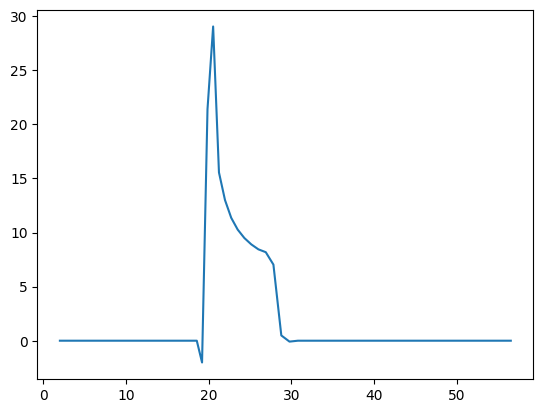

In [562]:
plt.figure()
for i in [5000]:
    s0 = geomz0(tx, rx, R, ix=i).squeeze()
    plt.plot(R.numpy(), s0.numpy())

In [563]:
s1 = geomz1(tx, rx, R).squeeze()

C:\Users\au646858\AppData\Local\Temp\ipykernel_23532\1683358857.py:4: RuntimeWarning: divide by zero encountered in divide
  axs[1].semilogx(R.numpy(), (s0-s1).numpy()/s0.numpy())
C:\Users\au646858\AppData\Local\Temp\ipykernel_23532\1683358857.py:4: RuntimeWarning: invalid value encountered in divide
  axs[1].semilogx(R.numpy(), (s0-s1).numpy()/s0.numpy())


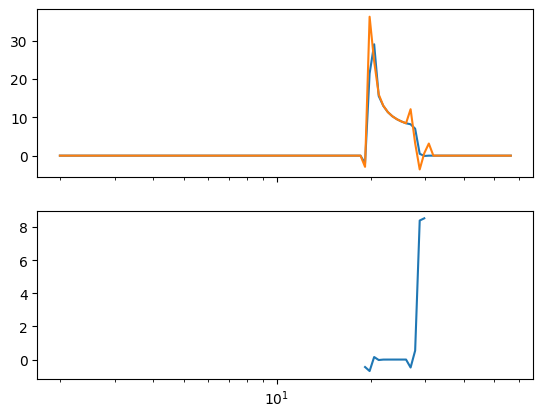

In [564]:
fig,axs = plt.subplots(2,1, sharex=True)
axs[0].semilogx(R.numpy(), s0.numpy())
axs[0].semilogx(R.numpy(), s1.numpy())
axs[1].semilogx(R.numpy(), (s0-s1).numpy()/s0.numpy())

